In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

In [3]:
df = pd.read_csv('/content/Metro_Interstate_Traffic_Volume.csv')

df.head()

,holiday,temp,rain_1h,snow_1h,clouds_all,weather_main,weather_description,date_time,traffic_volume
0,NaN,288.28,0.0,0.0,40,Clouds,scattered clouds,2012-10-02 09:00:00,5545
1,NaN,289.36,0.0,0.0,75,Clouds,broken clouds,2012-10-02 10:00:00,4516
2,NaN,289.58,0.0,0.0,90,Clouds,overcast clouds,2012-10-02 11:00:00,4767
3,NaN,290.13,0.0,0.0,90,Clouds,overcast clouds,2012-10-02 12:00:00,5026
4,NaN,291.14,0.0,0.0,75,Clouds,broken clouds,2012-10-02 13:00:00,4918


In [4]:
df.shape

(48204, 9)

In [5]:
df.info()
df.describe()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 48204 entries, 0 to 48203
Data columns (total 9 columns):
 #   Column               Non-Null Count  Dtype  
---  ------               --------------  -----  
 0   holiday              61 non-null     object 
 1   temp                 48204 non-null  float64
 2   rain_1h              48204 non-null  float64
 3   snow_1h              48204 non-null  float64
 4   clouds_all           48204 non-null  int64  
 5   weather_main         48204 non-null  object 
 6   weather_description  48204 non-null  object 
 7   date_time            48204 non-null  object 
 8   traffic_volume       48204 non-null  int64  
dtypes: float64(3), int64(2), object(4)
memory usage: 3.3+ MB


,temp,rain_1h,snow_1h,clouds_all,traffic_volume
count,48204.000000,48204.000000,48204.000000,48204.000000,48204.000000
mean,281.205870,0.334264,0.000222,49.362231,3259.818355
std,13.338232,44.789133,0.008168,39.015750,1986.860670
min,0.000000,0.000000,0.000000,0.000000,0.000000
25%,272.160000,0.000000,0.000000,1.000000,1193.000000
50%,282.450000,0.000000,0.000000,64.000000,3380.000000
75%,291.806000,0.000000,0.000000,90.000000,4933.000000
max,310.070000,9831.300000,0.510000,100.000000,7280.000000


**Understand the columns**

In [6]:
df.columns

Index(['holiday', 'temp', 'rain_1h', 'snow_1h', 'clouds_all', 'weather_main',
       'weather_description', 'date_time', 'traffic_volume'],
      dtype='object')

In [7]:
df.isnull().sum()

,0
holiday,48143
temp,0
rain_1h,0
snow_1h,0
clouds_all,0
weather_main,0
weather_description,0
date_time,0
traffic_volume,0


In [8]:
missing = pd.DataFrame({
    'Missing_Count': df.isnull().sum(),
    'Missing_Percentage': df.isnull().mean() * 100
})

missing

,Missing_Count,Missing_Percentage
holiday,48143,99.873454
temp,0,0.000000
rain_1h,0,0.000000
snow_1h,0,0.000000
clouds_all,0,0.000000
weather_main,0,0.000000
weather_description,0,0.000000
date_time,0,0.000000
traffic_volume,0,0.000000


In [9]:
df['holiday'].value_counts(dropna=False)

,count
holiday,
NaN,48143
Labor Day,7
Christmas Day,6
Thanksgiving Day,6
Martin Luther King Jr Day,6
New Years Day,6
Veterans Day,5
Columbus Day,5
Memorial Day,5


In [10]:
df.duplicated().sum()

np.int64(17)

In [11]:
df.drop_duplicates(inplace=True)

Convert temperature from Kelvin to Celsius

In [12]:
df['temp_celsius'] = df['temp'] - 273.15

In [13]:
df[['temp', 'temp_celsius']].head()

,temp,temp_celsius
0,288.28,15.13
1,289.36,16.21
2,289.58,16.43
3,290.13,16.98
4,291.14,17.99


Convert date_time

In [14]:
df['date_time'] = pd.to_datetime(df['date_time'])

In [15]:
df.info()

<class 'pandas.core.frame.DataFrame'>
Index: 48187 entries, 0 to 48203
Data columns (total 10 columns):
 #   Column               Non-Null Count  Dtype         
---  ------               --------------  -----         
 0   holiday              61 non-null     object        
 1   temp                 48187 non-null  float64       
 2   rain_1h              48187 non-null  float64       
 3   snow_1h              48187 non-null  float64       
 4   clouds_all           48187 non-null  int64         
 5   weather_main         48187 non-null  object        
 6   weather_description  48187 non-null  object        
 7   date_time            48187 non-null  datetime64[ns]
 8   traffic_volume       48187 non-null  int64         
 9   temp_celsius         48187 non-null  float64       
dtypes: datetime64[ns](1), float64(4), int64(2), object(3)
memory usage: 4.0+ MB


In [16]:
df['year'] = df['date_time'].dt.year
df['month'] = df['date_time'].dt.month
df['day'] = df['date_time'].dt.day
df['hour'] = df['date_time'].dt.hour
df['day_of_week'] = df['date_time'].dt.dayofweek

In [17]:
df['day_name'] = df['date_time'].dt.day_name()

**Create weekend feature**

In [18]:
df['is_weekend'] = (df['day_of_week'] >= 5).astype(int) #0 → Weekday 1 → Weekend

**Create holiday feature**

In [19]:
df['is_holiday'] = (df['holiday'] == 'None').astype(int)

In [20]:
df['is_holiday'].value_counts()   #0 → Normal day ,1 → Holiday

,count
is_holiday,
0,48187


Check traffic-volume outliers

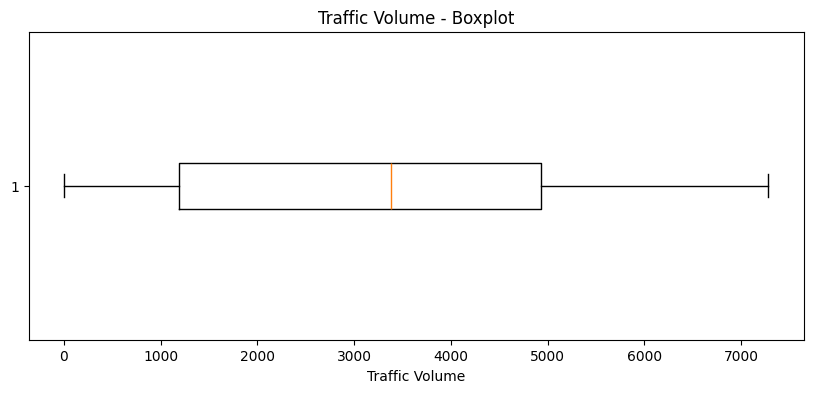

In [21]:
plt.figure(figsize=(10,4))
plt.boxplot(df['traffic_volume'], vert=False)
plt.xlabel('Traffic Volume')
plt.title('Traffic Volume - Boxplot')
plt.show()

**Basic EDA**

**1, Traffic-volume distribution** #This tells you how frequently low, medium and high traffic volumes occur.

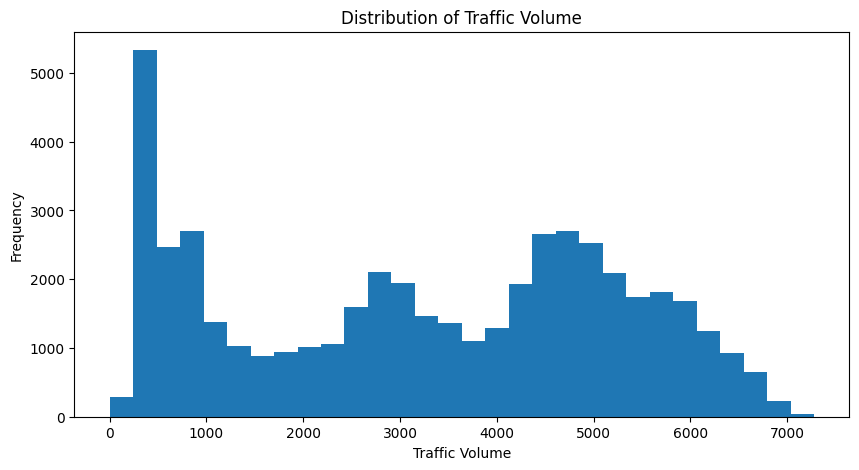

In [22]:
plt.figure(figsize=(10,5))
plt.hist(df['traffic_volume'], bins=30)
plt.xlabel('Traffic Volume')
plt.ylabel('Frequency')
plt.title('Distribution of Traffic Volume')
plt.show()

**Hourly traffic analysis** #Traffic volume varies significantly by hour, with clear peak periods associated with commuting hours.

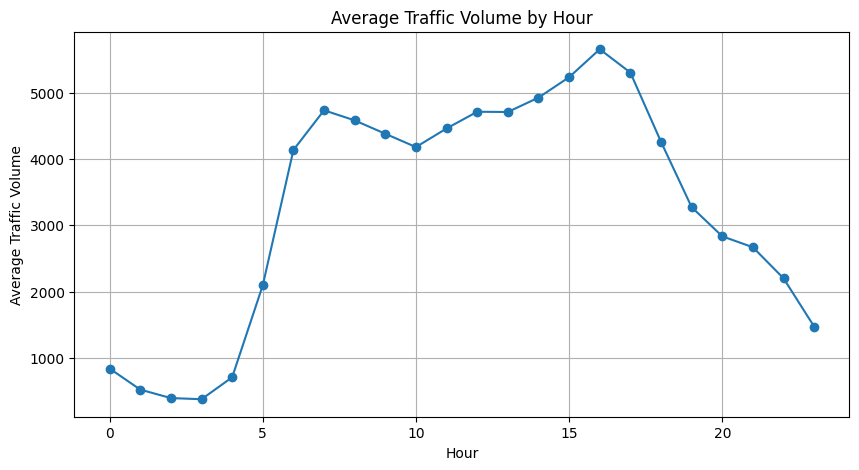

In [23]:
hourly_traffic = df.groupby('hour')['traffic_volume'].mean()

plt.figure(figsize=(10,5))
hourly_traffic.plot(marker='o')

plt.xlabel('Hour')
plt.ylabel('Average Traffic Volume')
plt.title('Average Traffic Volume by Hour')
plt.grid()
plt.show()

**Daily traffic analysis**  #Which day has the highest average traffic?

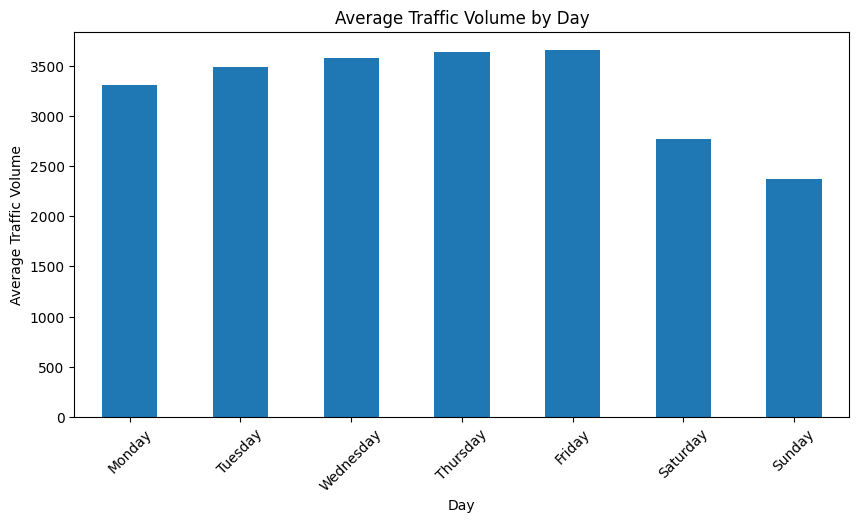

In [24]:
day_order = [
    'Monday',
    'Tuesday',
    'Wednesday',
    'Thursday',
    'Friday',
    'Saturday',
    'Sunday'
]

daily_traffic = (
    df.groupby('day_name')['traffic_volume']
      .mean()
      .reindex(day_order)
)

plt.figure(figsize=(10,5))
daily_traffic.plot(kind='bar')

plt.xlabel('Day')
plt.ylabel('Average Traffic Volume')
plt.title('Average Traffic Volume by Day')
plt.xticks(rotation=45)
plt.show()

**Weekday vs weekend analysis**    

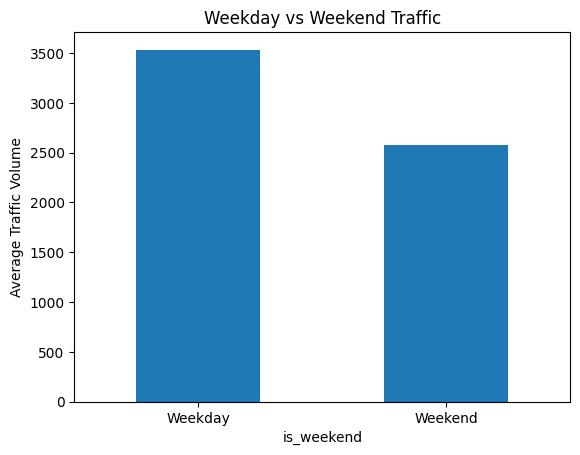

In [25]:
weekend_traffic = df.groupby('is_weekend')['traffic_volume'].mean()

weekend_traffic.plot(kind='bar')

plt.xticks([0,1], ['Weekday', 'Weekend'], rotation=0)
plt.ylabel('Average Traffic Volume')
plt.title('Weekday vs Weekend Traffic')
plt.show()

**Monthly traffic pattern**  #This shows whether traffic changes seasonally.

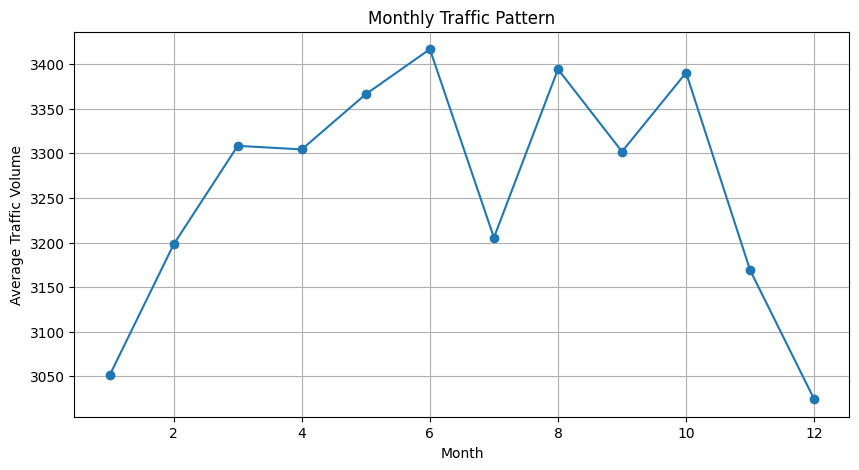

In [26]:
monthly_traffic = df.groupby('month')['traffic_volume'].mean()

monthly_traffic.plot(
    kind='line',
    marker='o',
    figsize=(10,5)
)

plt.xlabel('Month')
plt.ylabel('Average Traffic Volume')
plt.title('Monthly Traffic Pattern')
plt.grid()
plt.show()

**Weather vs traffic analysis**

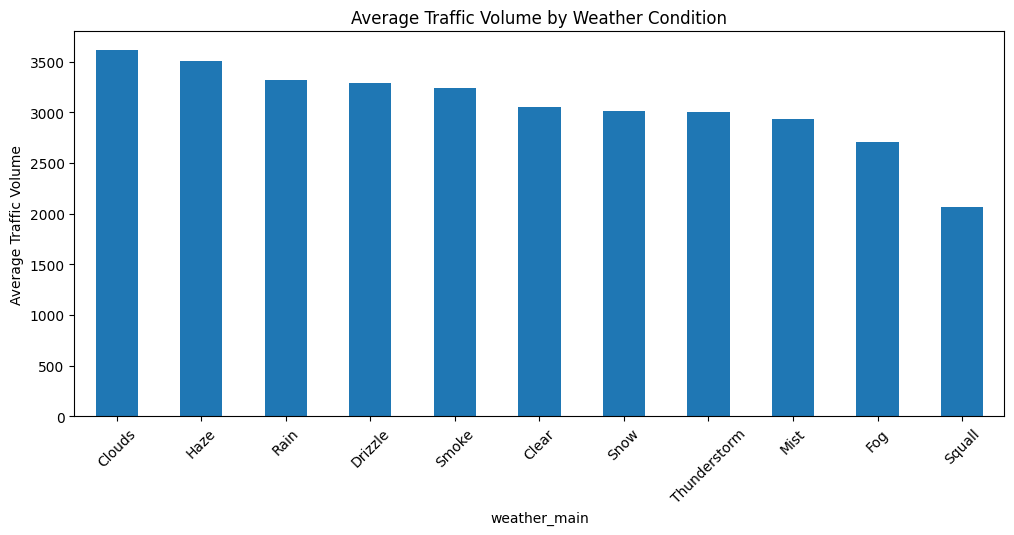

In [27]:
weather_traffic = (
    df.groupby('weather_main')['traffic_volume']
      .mean()
      .sort_values(ascending=False)
)

weather_traffic.plot(
    kind='bar',
    figsize=(12,5)
)

plt.ylabel('Average Traffic Volume')
plt.title('Average Traffic Volume by Weather Condition')
plt.xticks(rotation=45)
plt.show()

**Rain vs traffic**

Create new feature # **is_raining**

In [28]:
df['is_raining'] = (df['rain_1h'] > 0).astype(int)

In [29]:
df.groupby('is_raining')['traffic_volume'].mean()

,traffic_volume
is_raining,
0,3257.119633
1,3291.845688


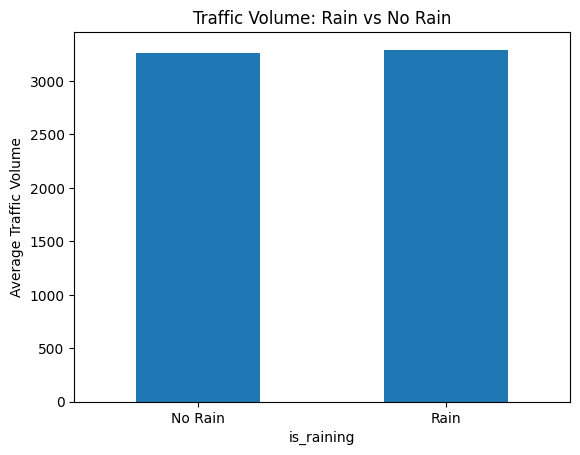

In [30]:
df.groupby('is_raining')['traffic_volume'].mean().plot(kind='bar')

plt.xticks([0,1], ['No Rain', 'Rain'], rotation=0)
plt.ylabel('Average Traffic Volume')
plt.title('Traffic Volume: Rain vs No Rain')
plt.show()

**Holiday vs normal-day traffic**

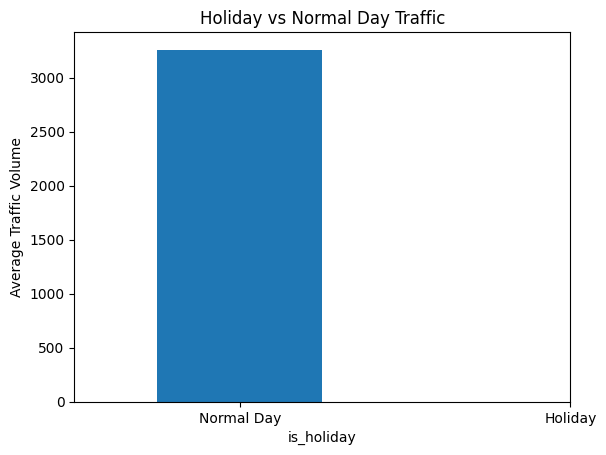

In [31]:
df.groupby('is_holiday')['traffic_volume'].mean().plot(kind='bar')

plt.xticks([0,1], ['Normal Day', 'Holiday'], rotation=0)
plt.ylabel('Average Traffic Volume')
plt.title('Holiday vs Normal Day Traffic')
plt.show()

**Create congestion levels**

In [32]:
df['congestion_level'] = pd.qcut(
    df['traffic_volume'],
    q=4,
    labels=['Low', 'Moderate', 'High', 'Severe']
)

In [33]:
df['congestion_level'].value_counts() #This divides the dataset into four approximately equal groups.

,count
congestion_level,
High,12054
Moderate,12049
Low,12047
Severe,12037


In [34]:
def congestion_level(volume):
    if volume < 1500:
        return 'Low'
    elif volume < 3000:
        return 'Moderate'
    elif volume < 4500:
        return 'High'
    else:
        return 'Severe'

df['congestion_level'] = df['traffic_volume'].apply(congestion_level)

**Check congestion-level distribution**

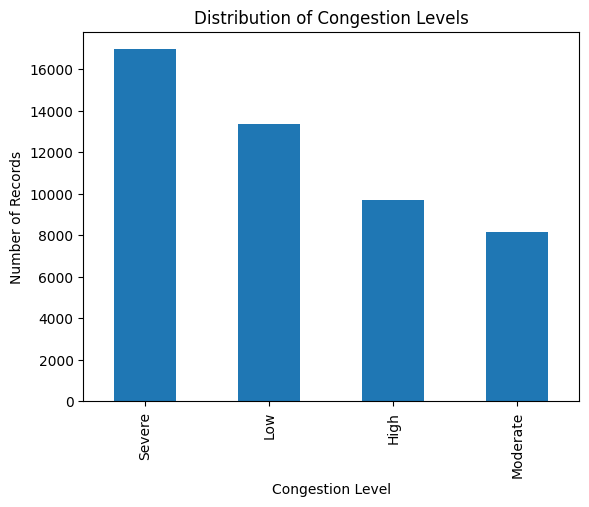

In [35]:
df['congestion_level'].value_counts().plot(kind='bar')

plt.xlabel('Congestion Level')
plt.ylabel('Number of Records')
plt.title('Distribution of Congestion Levels')
plt.show()

**Day × hour congestion heatmap**

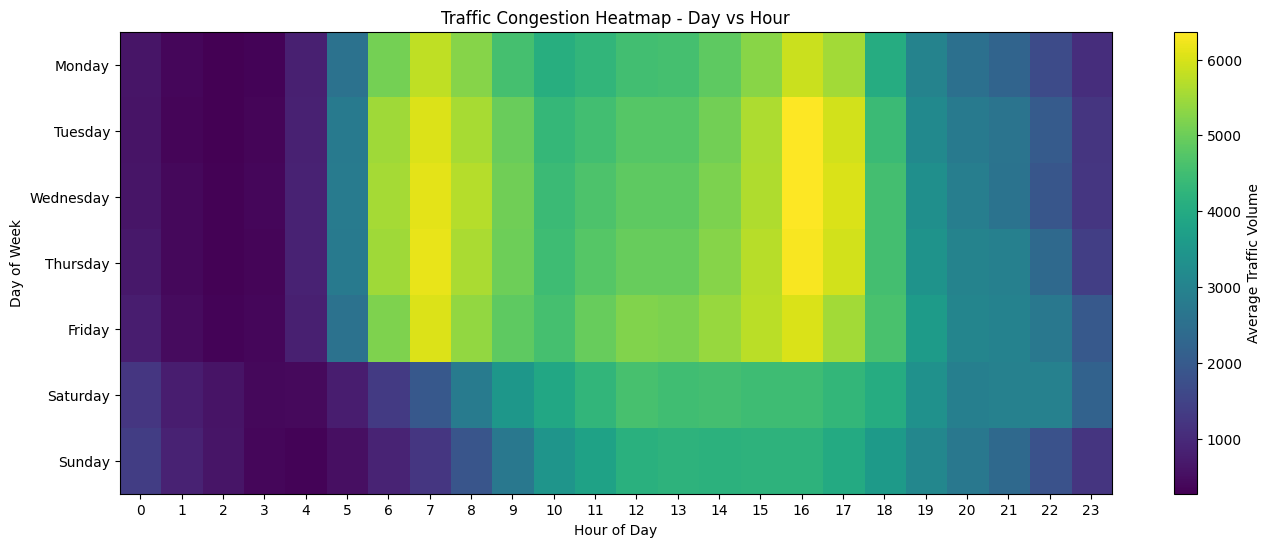

In [36]:
heatmap_data = df.pivot_table(
    values='traffic_volume',
    index='day_name',
    columns='hour',
    aggfunc='mean'
)

heatmap_data = heatmap_data.reindex(day_order)

plt.figure(figsize=(16,6))
plt.imshow(heatmap_data, aspect='auto')

plt.colorbar(label='Average Traffic Volume')
plt.xticks(range(24), range(24))
plt.yticks(range(7), day_order)

plt.xlabel('Hour of Day')
plt.ylabel('Day of Week')
plt.title('Traffic Congestion Heatmap - Day vs Hour')

plt.show()  #It shows which day + hour combinations experience the heaviest traffic?

**Find the busiest hours**

In [37]:
df.groupby('hour')['traffic_volume'] \
  .mean() \
  .sort_values(ascending=False) \
  .head(10) #Top 10 busiest hours of day.

,traffic_volume
hour,
16,5663.756539
17,5310.076048
15,5240.459907
14,4931.888776
7,4740.181337
12,4718.031730
13,4714.652836
8,4587.497115
11,4465.569231


In [38]:
busiest_periods = (
    df.groupby(['day_name', 'hour'])['traffic_volume']
      .mean()
      .sort_values(ascending=False)
      .head(10)
      .reset_index()
)

busiest_periods  #7 AM → Morning rush hour
#4 PM (hour 16) → Evening rush hour
#5 PM (hour 17) → Evening rush hour

,day_name,hour,traffic_volume
0,Wednesday,16,6367.467577
1,Tuesday,16,6366.796992
2,Thursday,16,6313.568421
3,Thursday,7,6168.611486
4,Wednesday,7,6120.721649
5,Tuesday,7,6043.778947
6,Friday,7,6038.904437
7,Friday,16,6026.752650
8,Wednesday,17,6018.631387
9,Thursday,17,5950.033457


In [39]:
df.head()


,holiday,temp,rain_1h,snow_1h,clouds_all,weather_main,weather_description,date_time,traffic_volume,temp_celsius,year,month,day,hour,day_of_week,day_name,is_weekend,is_holiday,is_raining,congestion_level
0,NaN,288.28,0.0,0.0,40,Clouds,scattered clouds,2012-10-02 09:00:00,5545,15.13,2012,10,2,9,1,Tuesday,0,0,0,Severe
1,NaN,289.36,0.0,0.0,75,Clouds,broken clouds,2012-10-02 10:00:00,4516,16.21,2012,10,2,10,1,Tuesday,0,0,0,Severe
2,NaN,289.58,0.0,0.0,90,Clouds,overcast clouds,2012-10-02 11:00:00,4767,16.43,2012,10,2,11,1,Tuesday,0,0,0,Severe
3,NaN,290.13,0.0,0.0,90,Clouds,overcast clouds,2012-10-02 12:00:00,5026,16.98,2012,10,2,12,1,Tuesday,0,0,0,Severe
4,NaN,291.14,0.0,0.0,75,Clouds,broken clouds,2012-10-02 13:00:00,4918,17.99,2012,10,2,13,1,Tuesday,0,0,0,Severe
